# CardioAmostra — Análise exploratória (Fase 1)

Responsável: Pessoa 1 (Dados). Este notebook só explora; nada no app depende dele.

Perguntas:
1. Qual a proporção de doentes em cada base? (critério de pronto da Fase 1)
2. Como a prevalência varia por faixa etária e sexo?
3. Há valores ausentes?

As bases brutas ficam em `dados/brutos/` (veja o LEIA-ME de lá).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from cardioamostra import dados

FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

# Paleta do plano (Interface de referência)
DOENTE, SAUDAVEL = "#B0124F", "#C9CFDA"
TEXTO, TEXTO2, BORDA, FUNDO = "#1B2236", "#586178", "#E7E0E1", "#FFFBFA"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": "#FFFFFF", "axes.edgecolor": BORDA,
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11,
})
NOMES = {"brfss": "BRFSS 2020", "insuficiencia": "Insuficiência cardíaca", "cleveland": "Cleveland"}
disponiveis = [b for b in dados.BASES if dados.disponivel(b)]
print("Bases encontradas:", disponiveis or "nenhuma — baixe os arquivos primeiro")

Bases encontradas: ['brfss', 'insuficiencia', 'cleveland']


## 1. Tamanho e proporção de doentes

In [2]:
tabela = dados.resumo()
tabela["prevalencia_%"] = (tabela["prevalencia"] * 100).round(2)
tabela

,base,linhas,variaveis,positivos,prevalencia,prevalencia_%
0,brfss,301717,25,27261,0.0904,9.04
1,insuficiencia,299,11,96,0.3211,32.11
2,cleveland,303,22,139,0.4587,45.87


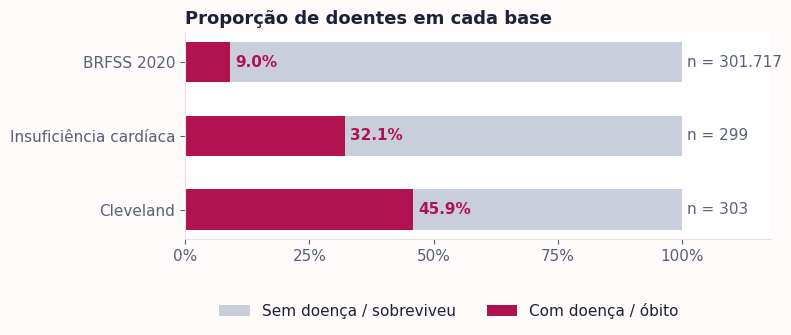

In [3]:
t = tabela.set_index("base").loc[disponiveis]
fig, ax = plt.subplots(figsize=(8, 0.9 * len(t) + 1.2))
rotulos = [NOMES[b] for b in t.index]
ax.barh(rotulos, 1, color=SAUDAVEL, height=0.55, label="Sem doença / sobreviveu")
ax.barh(rotulos, t["prevalencia"], color=DOENTE, height=0.55, label="Com doença / óbito")
for i, (p, n) in enumerate(zip(t["prevalencia"], t["linhas"], strict=True)):
    ax.text(p + 0.01, i, f"{p:.1%}", va="center", color=DOENTE, fontweight="bold")
    ax.text(1.01, i, f"n = {n:,}".replace(",", "."), va="center", color=TEXTO2)
ax.set_xlim(0, 1.18)
ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.invert_yaxis()
ax.set_title("Proporção de doentes em cada base", loc="left")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.45), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(FIGURAS / "proporcao_doentes.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Prevalência por faixa etária e sexo (BRFSS)

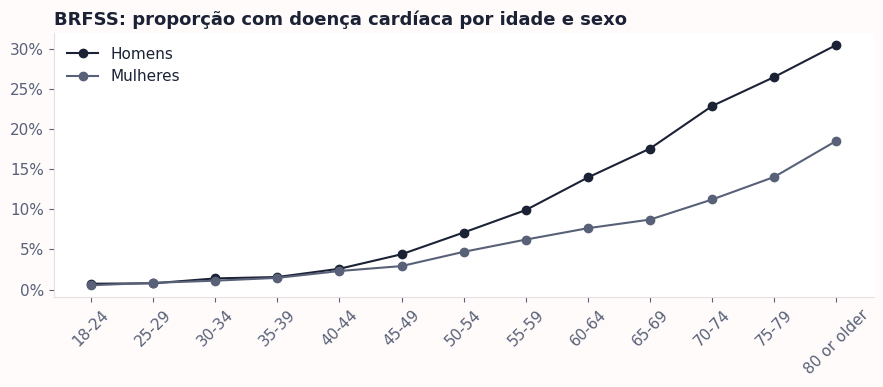

Sex,Female,Male
AgeCategory,,
18-24,0.5,0.7
25-29,0.8,0.8
30-34,1.1,1.4
35-39,1.5,1.6
40-44,2.3,2.6
45-49,2.9,4.4
50-54,4.7,7.1
55-59,6.2,9.9
60-64,7.6,14.0


In [4]:
if "brfss" in disponiveis:
    b = dados.limpar("brfss")
    b["AgeCategory"] = pd.Categorical(b["AgeCategory"], dados.ORDEM_IDADE, ordered=True)
    prev = b.groupby(["AgeCategory", "Sex"], observed=True)["alvo"].mean().unstack()
    fig, ax = plt.subplots(figsize=(9, 4))
    for sexo, cor, nome in (("Male", TEXTO, "Homens"), ("Female", TEXTO2, "Mulheres")):
        if sexo in prev:
            ax.plot(prev.index.astype(str), prev[sexo], marker="o", color=cor, label=nome)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title("BRFSS: proporção com doença cardíaca por idade e sexo", loc="left")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURAS / "brfss_idade_sexo.png", dpi=150, bbox_inches="tight")
    plt.show()
    display((prev * 100).round(1))

## 3. Prevalência por sexo nas bases clínicas

In [5]:
linhas = []
for base in ("insuficiencia", "cleveland"):
    if base in disponiveis:
        d = dados.limpar(base)
        for sexo, g in d.groupby("sex"):
            linhas.append({"base": NOMES[base], "sexo": "Masculino" if sexo == 1 else "Feminino",
                           "n": len(g), "prevalencia_%": round(g["alvo"].mean() * 100, 1)})
if "brfss" in disponiveis:
    for sexo, g in dados.limpar("brfss").groupby("Sex"):
        rotulo = "Masculino" if sexo == "Male" else "Feminino"
        linhas.append({"base": NOMES["brfss"], "sexo": rotulo,
                       "n": len(g), "prevalencia_%": round(g["alvo"].mean() * 100, 1)})
pd.DataFrame(linhas)

,base,sexo,n,prevalencia_%
0,Insuficiência cardíaca,Feminino,105,32.4
1,Insuficiência cardíaca,Masculino,194,32.0
2,Cleveland,Feminino,97,25.8
3,Cleveland,Masculino,206,55.3
4,BRFSS 2020,Feminino,159671,7.0
5,BRFSS 2020,Masculino,142046,11.3


## 4. Valores ausentes e duplicatas (arquivos brutos)

In [6]:
info = []
for base in disponiveis:
    bruto = dados.ler_bruto(base)
    aus = bruto.isna().sum()
    info.append({
        "base": NOMES[base],
        "linhas_brutas": len(bruto),
        "duplicatas": int(bruto.duplicated().sum()),
        "celulas_ausentes": int(aus.sum()),
        "colunas_com_ausentes": ", ".join(f"{k} ({v})" for k, v in aus[aus > 0].items()) or "—",
    })
pd.DataFrame(info)

,base,linhas_brutas,duplicatas,celulas_ausentes,colunas_com_ausentes
0,BRFSS 2020,319795,18078,0,—
1,Insuficiência cardíaca,299,0,0,—
2,Cleveland,303,0,6,"ca (4), thal (2)"


## 5. Achados

1. **Três níveis de desbalanceamento.** BRFSS: 9,04% de doentes (27.261 de 301.717, razão ≈ 10:1). Insuficiência cardíaca: 32,1% de óbitos (96 de 299, ≈ 2:1). Cleveland: 45,9% (139 de 303), quase equilibrada; serve de controle.
2. **Duplicatas.** A BRFSS tinha 319.795 linhas, com 18.078 repetidas; removidas, sobram 301.717, como no artigo da IJACSA. As outras bases não têm duplicatas.
3. **Ausentes.** Só a Cleveland tem: 4 em `ca` e 2 em `thal`, preenchidos com a moda para manter as 303 linhas.
4. **Idade.** Na BRFSS a prevalência cresce de forma contínua com a idade: menos de 1% entre 18 e 24 anos e 30,5% nos homens com 80 anos ou mais. Idade deve ser a variável mais forte do modelo.
5. **Sexo.** Homens têm mais doença cardíaca na BRFSS (11,3% contra 7,0%) e na Cleveland (55,3% contra 25,8%), e a diferença aumenta com a idade (aos 65–69: 17,6% contra 8,7%). Na insuficiência cardíaca, o óbito é igual entre os sexos (32,0% e 32,4%).
6. **Vazamento evitado.** A coluna `time` da insuficiência cardíaca (dias de acompanhamento) foi removida, porque só é conhecida depois do desfecho.
7. **Consequência para a amostragem.** Na Cleveland o SMOTE e a subamostragem quase não mudam a distribuição; na base de insuficiência há só 96 positivos, então cada parte de treino da validação cruzada tem cerca de 77, o suficiente para o SMOTE com 5 vizinhos.